![Banner](../images/09_05_banner_rs_hyperspect.png)


# Introduction to Imaging Spectroscopy

A multispectral sensor such as Landsat or Sentinel-2 records a handful of broad bands. An
imaging spectrometer records hundreds of narrow, contiguous bands, so every pixel carries a
near-continuous spectrum from the visible to the shortwave infrared. That spectrum holds the
absorption features of pigments, water, minerals and gases, which is why hyperspectral data can
tell kaolinite from calcite, estimate leaf chlorophyll or map a methane plume. This notebook
introduces the physics, the sensors and the data products, then opens the chapter data with
`geolattice.rsense.hyperspectral`: nine Planet Tanager scenes, a laboratory cube of white powders and
the OHS and Pavia benchmark images used later in the chapter.

Twelve notebooks take a cube from the sensor file to a map.

- **Introduction to Imaging Spectroscopy.** This notebook. Narrow bands and the sensors, then the chapter data: nine Planet Tanager scenes, a laboratory powder cube, and the OHS and Pavia benchmarks.
- **Reading and Exploring Hyperspectral Data.** Read HDF5, NetCDF, ENVI, band GeoTIFFs and PNG folders into one GeoLattice cube, and georeference swath and OHS scenes.
- **Preprocessing Hyperspectral Cubes.** Drop bad bands, mask clouds, turn radiance into reflectance, and smooth, differentiate or continuum-remove spectra.
- **Dimensionality Reduction and Band Selection.** Compress Tanager and Pavia with PCA, MNF and ICA, and denoise by keeping the signal components.
- **Narrowband Indices and Vegetation Analysis.** Target chlorophyll, the red edge, carotenoids, leaf water, cellulose and lignin with the narrowband index catalogue.
- **Biophysical and Biochemical Trait Retrieval.** Simulate canopies with PROSAIL and retrieve LAI, chlorophyll and water with partial least squares, random forest and Gaussian processes.
- **Spectral Libraries and Spectral Matching.** Build spectral libraries and compare spectra by spectral angle, information divergence, correlation and Euclidean distance.
- **Endmember Extraction and Spectral Unmixing.** Extract endmembers and estimate mixture fractions, first on a synthetic scene with known answers.
- **Target and Anomaly Detection.** Find a known material, or any unusual pixel, against a statistical model of the background.
- **Greenhouse Gas Plume Detection.** Build a methane absorption spectrum from HITRAN and map enhancement over oil fields.
- **Thematic Applications Across Tanager Scenes.** Burn severity at Malibu, snow and ice on Baffin Island, coastal water off Venezuela, and iron oxides in Bosnia and Herzegovina.
- **Deep Learning for Hyperspectral Classification.** Train a 1D CNN, a 3D CNN, HybridSN and a spectral transformer on Pavia Centre, against a random forest and spectral angle.


## Overview

### What imaging spectroscopy measures

Light reflected from a surface carries the fingerprint of what it met. Chlorophyll absorbs blue
and red light, leaf water absorbs near 970, 1200, 1450 and 1940 nm, clays absorb near 2200 nm,
carbonates near 2340 nm and iron oxides near 900 nm. Most of these features are 10 to 50 nm
wide. A broadband sensor averages them away; a spectrometer with 5 to 10 nm bands resolves them.

**Imaging spectroscopy** (also called hyperspectral imaging) measures that spectrum for every
pixel of an image. The term was coined for NASA's Airborne Imaging Spectrometer in the early
1980s, and AVIRIS (1987) set the template still in use: about 224 contiguous bands at 10 nm from
400 to 2500 nm.

The key ideas are:

- **Spectral range**: the wavelengths covered. VNIR is about 400 to 1000 nm, SWIR about 1000 to
  2500 nm. VNIR-only sensors (DESIS, OHS, PACE OCI) see pigments and water colour; VSWIR sensors
  (EMIT, EnMAP, PRISMA, Tanager) add the minerals, leaf water, cellulose and greenhouse gases.
- **Spectral sampling**: the spacing between band centres, for example 5 nm.
- **Spectral resolution**: the width of each band's spectral response function, usually given as
  the full width at half maximum (**FWHM**). Sampling a little finer than the FWHM (Nyquist) lets
  the spectrum be reconstructed without gaps.
- **Signal to noise ratio (SNR)**: narrow bands collect few photons, so noise matters much more
  than in multispectral data. SNR is lowest at the ends of the range and inside absorption bands.

| Class | Bands | Typical width | Example |
|---|---|---|---|
| Panchromatic | 1 | 300 to 400 nm | Landsat 8 band 8 |
| Multispectral | 4 to 15 | 20 to 200 nm | Sentinel-2 MSI, Landsat OLI |
| Superspectral | 15 to 50 | 10 to 20 nm | OHS (32 bands), MERIS |
| Hyperspectral | 100 to 500 | 3 to 12 nm | EMIT, EnMAP, PRISMA, Tanager |

### The hyperspectral data cube

Stacking the band images gives a three dimensional **cube**: two spatial axes and one spectral
axis. A Tanager scene is about 426 bands by 700 rows by 800 columns, close to 1 GB as 32 bit
floats. Each pixel is a spectrum; each band is an image. Three storage layouts are common:
band sequential (BSQ, one image after another), band interleaved by line (BIL) and band
interleaved by pixel (BIP). Products arrive as ENVI binary plus header, HDF5 or HDF-EOS5,
NetCDF or multiband GeoTIFF.

### How imaging spectrometers are built

- **Whiskbroom** scanners sweep a mirror across track and disperse one pixel at a time onto a
  line detector (AVIRIS Classic, HyMap). Simple optics, but moving parts and short dwell time.
- **Pushbroom** spectrometers image a whole line across track through a slit; a grating or prism
  spreads it over a 2-D detector (space by wavelength), and the platform's motion builds the
  image line by line. Almost all modern sensors (EMIT, EnMAP, PRISMA, Tanager, AVIRIS-NG, HySpex,
  Specim) are pushbroom. Each detector column has its own response, which causes **striping**.
- **Snapshot** and **tunable filter** cameras capture all bands at once or step through filters;
  they are common in laboratories, microscopes and drones. Filter based satellites such as OHS
  sit between multispectral and hyperspectral.

Silicon detectors cover the VNIR; mercury cadmium telluride (HgCdTe) detectors, cooled to below
about 150 K, cover the SWIR. Two instrument artefacts deserve a name: **spectral smile** (the band
centres shift slightly across the swath) and **keystone** (a pixel's footprint shifts slightly
with wavelength).

### From radiance to reflectance

The sensor measures **at-sensor radiance** (W m⁻² sr⁻¹ µm⁻¹): sunlight that crossed the
atmosphere twice and bounced off the surface, plus light scattered by air and aerosols. To compare
pixels, dates and sensors it must be converted to **surface reflectance**, the fraction of incident
light the surface reflects (0 to 1). Atmospheric correction codes such as ISOFIT, ATCOR, FLAASH
and the mission processors invert a radiative transfer model per pixel, retrieving water vapour
and aerosols on the way.

The atmosphere also leaves its own absorption bands, which mark where surface information is
weak or absent:

| Feature | Wavelength (nm) | Cause |
|---|---|---|
| Oxygen A band | 760 | O₂ |
| Water vapour | 940, 1140 | H₂O |
| Strong water vapour (opaque) | 1350 to 1450, 1800 to 1950 | H₂O |
| Carbon dioxide | 2010, 2060 | CO₂ |
| Methane | 2200 to 2400 (strongest near 2300) | CH₄ |

The opaque water bands are usually dropped as **bad bands**. The gas bands, on the other hand,
are a signal in their own right: the methane notebook later in this chapter uses them.

Processing levels follow a common pattern:

| Level | Content | Tanager product |
|---|---|---|
| L1B | Calibrated at-sensor radiance in sensor geometry | `basic_radiance_hdf5` |
| L1C / ortho | Radiance resampled to a map grid | `ortho_radiance_hdf5` |
| L2A | Surface reflectance with uncertainty, cloud masks, water vapour, aerosol | `ortho_sr_hdf5` |
| L2B / L3 | Derived maps (minerals, gas enhancement, traits, mosaics) | `ortho_ql_ch4` quick look |

### Sensors and missions

| Sensor | Platform | Years | Bands | Range (nm) | Sampling | Pixel |
|---|---|---|---|---|---|---|
| AVIRIS Classic | NASA aircraft | 1987 to 2021 | 224 | 400 to 2500 | 10 nm | 2 to 20 m |
| AVIRIS-NG | NASA aircraft | 2012 onward | about 425 | 380 to 2510 | 5 nm | 0.3 to 9 m |
| Hyperion | EO-1 | 2000 to 2017 | 220 | 357 to 2576 | 10 nm | 30 m |
| PRISMA | ASI | 2019 onward | about 239 | 400 to 2500 | 12 nm or finer | 30 m |
| DESIS | ISS (DLR, Teledyne) | 2018 onward | 235 | 400 to 1000 | 2.55 nm | 30 m |
| GF-5 AHSI | China | 2018 onward | 330 | 400 to 2500 | 5 and 10 nm | 30 m |
| OHS | Zhuhai-1 (Orbita) | 2018 onward | 32 | about 450 to 950 | about 15 nm | 10 m |
| EnMAP | DLR | 2022 onward | about 224 | 420 to 2450 | 6.5 and 10 nm | 30 m |
| EMIT | ISS (NASA) | 2022 onward | 285 | 381 to 2493 | 7.4 nm | 60 m |
| PACE OCI | NASA | 2024 onward | hyperspectral UV to NIR plus SWIR bands | 340 to 2260 | 5 nm (UV to NIR) | about 1.2 km |
| Tanager-1 | Planet / Carbon Mapper | 2024 onward | 426 | 376 to 2499 | about 5 nm | 30 m |
| CHIME | ESA Copernicus | planned | about 200+ | 400 to 2500 | 10 nm or finer | 30 m |
| SBG VSWIR | NASA | planned | about 200+ | 380 to 2500 | 10 nm or finer | 30 m |

Airborne systems (AVIRIS-NG, AVIRIS-3, HyMap, HySpex, CASI and SASI), drone cameras (Headwall,
Specim, Cubert) and laboratory push broom cameras share the same data model at finer pixels.

### Applications

- **Vegetation**: chlorophyll, carotenoids, anthocyanins, leaf water, nitrogen, lignin and
  cellulose, plant stress and species mapping; LAI and canopy chlorophyll from radiative transfer
  models such as PROSAIL.
- **Geology and soils**: mineral maps from diagnostic absorption features (clays, micas,
  carbonates, iron oxides), soil organic carbon and texture, mine waste monitoring.
- **Water**: chlorophyll a, phycocyanin (cyanobacteria), suspended sediment, coloured dissolved
  organic matter, shallow water bathymetry and benthic habitats.
- **Snow and ice**: grain size, liquid water, light absorbing impurities (dust, algae, soot).
- **Greenhouse gases**: methane and carbon dioxide plumes from oil and gas, coal, landfills and
  livestock, with source emission rates.
- **Fire**: active fire temperature, burn severity, post fire recovery.
- **Urban and industry**: roofing and paving materials, plastics, impervious surfaces.
- **Laboratory and industry**: food quality and contamination, sorting, pharmaceuticals,
  art conservation and forensics.

### Accessibility

| Source | Data | Access |
|---|---|---|
| NASA Earthdata (LP DAAC) | EMIT L1B radiance, L2A reflectance, L2B minerals and CH₄ | Free with an Earthdata login; `earthaccess` |
| DLR EOWEB GeoPortal | EnMAP L1B to L2A, DESIS | Free for science after registration |
| ASI PRISMA portal | PRISMA L1 to L2D | Free for registered users |
| Planet | Tanager core imagery (open sample scenes on a STAC catalogue), commercial tasking | Open sample data; commercial license |
| Carbon Mapper data portal | Tanager methane and CO₂ plumes and emission rates | Free, open |
| USGS EarthExplorer | EO-1 Hyperion archive | Free |
| ORNL DAAC and JPL AVIRIS portal | AVIRIS Classic, AVIRIS-NG, AVIRIS-3 campaigns | Free |
| Orbita | OHS scenes | Commercial (sample scenes on request) |

**Python tools:** `spectral` (SPy) for ENVI files and classic algorithms, `hylite` and
`pysptools` for geology and unmixing, `earthaccess` for NASA search and download, `h5py`,
`xarray` and `rioxarray` for HDF5 and NetCDF, and `isofit` for atmospheric correction. GeoLattice
wraps the reading, preprocessing and analysis steps in one module with one cube convention.


## Hyperspectral Imaging with GeoLattice

`geolattice.rsense.hyperspectral` (imported here as `hs`) holds every function the chapter uses.
Cubes are `xarray.DataArray` objects with dimensions `(band, y, x)` and band coordinates
`wavelength` (nm), `fwhm` (nm) and `good` (bool). Swath products that are not yet on a map grid
use `(band, line, sample)` in the same way. Readers exist for ENVI, EMIT, EnMAP, PRISMA, Tanager,
OHS, AVIRIS and band described GeoTIFFs, and every analysis function (preprocessing, dimensionality
reduction, indices, libraries, unmixing, detection, traits) accepts and returns this layout.

### Learning objectives

1. Explain spectral range, sampling, FWHM and SNR, and why narrow bands resolve absorption
   features that broad bands miss.
2. Describe the hyperspectral data cube, the main sensor designs and the processing levels from
   radiance to reflectance.
3. Know the current spaceborne imaging spectrometers and where to get their data.
4. Build a cube from separate band images with `hs.as_cube` and query it by wavelength.
5. Read a Planet Tanager surface reflectance product and its ancillary layers with
   `hs.read_tanager` and `hs.read_tanager_ancillary`.
6. Compare radiance and reflectance spectra and recognise atmospheric absorption bands.
7. Extract and compare spectral signatures of vegetation, soil, water, snow, urban surfaces and a
   burn scar.

### Data

| Dataset | Folder (under `data/`) | Content |
|---|---|---|
| Planet Tanager core imagery | `Tanger/<category>/<scene>/` | Nine open sample scenes (agriculture, natural lands, urban, coastal, energy and mining, greenhouse gas plume, fire, snow and ice, ROCX 2025), each with ortho TOA radiance and surface reflectance (HDF-EOS5), usable data mask, visual GeoTIFF, thumbnail and STAC item; index in `Tanger/scenes.json` |
| HACARUS laboratory cubes | `archive/data/` | Five NIR scenes (coffee, rice, sugar salt flour, the same with a contaminant, yatsuhashi), 96 PNG band images from 1293 to 2215 nm, 192 by 256 pixels (CC BY-NC 4.0) |
| OHS sample scene | `10m_OH2_Hyperspectral_Sample/Spanish-OHS/` | Orbita OHS L1 scene over Extremadura, Spain (July 2018), 32 band GeoTIFFs with RPCs, 10 m |
| Pavia Centre | `Pavia/pavia.npy` | ROSIS airborne cube, 1096 by 715 pixels, 102 bands (430 to 860 nm), 1.3 m |

All files are already in the chapter's `data/` folder; nothing is downloaded.

### Contents

- Setup
- Why narrow bands matter
- The GeoLattice cube: a laboratory example
- The chapter data at a glance
- A first look at a Tanager scene
- Radiance, reflectance and the atmosphere
- Spectral signatures across Tanager scenes
- Interactive exploration
- Summary and exercises


## Setup

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
import warnings  # warning control
warnings.filterwarnings("ignore")  # hide routine library warnings (e.g. non-georeferenced PNG and RPC files)

import json  # read the Tanager scene index
import re  # parse wavelengths from file names
from pathlib import Path  # file paths

import numpy as np  # arrays
import pandas as pd  # tables
import matplotlib.pyplot as plt  # figures
import rasterio  # raster metadata
from PIL import Image  # read PNG band images and thumbnails

import geolattice  # GeoLattice
from geolattice.rsense import hyperspectral as hs  # hyperspectral cubes, readers and tools

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
DATA = Path("../../../../Data/08_remote_sensing/08_05_HyperSpectral")  # data folder next to this notebook
TANAGER = DATA / "Tanger"  # Planet Tanager sample scenes
print("GeoLattice", geolattice.__version__)  # library version used for this notebook

GeoLattice 0.3.43


## Why narrow bands matter

`hs.synthetic_library` returns idealised spectra of six materials built from Gaussian absorption
features at 1 nm steps. They are teaching spectra, not measurements, but their features sit at the
right wavelengths. Below they are convolved with the band responses of Tanager (426 bands, about
5.5 nm FWHM), Landsat 8/9 OLI and Sentinel-2 MSI with `hs.resample_spectral`, which applies a
Gaussian response function for each target band.


In [2]:
lib = hs.synthetic_library(np.arange(400.0, 2501.0, 1.0))  # six idealised spectra at 1 nm
print(lib.names)  # material names

# Treat the library as a tiny cube: bands x 1 row x 6 columns, so every cube function applies.
lib_cube = hs.as_cube(lib.spectra.T[:, None, :], lib.wavelengths)

# Tanager band centres and FWHM, read from one pixel of a surface reflectance file.
sr_agri = next((TANAGER / "agriculture").glob("*/*_ortho_sr_hdf5.h5"))  # agriculture scene
probe = hs.read_tanager(sr_agri, window=(slice(0, 1), slice(0, 1)))  # 1 x 1 pixel read
tan_wl, tan_fwhm = probe["wavelength"].values, probe["fwhm"].values  # band centres and widths
print(f"Tanager: {tan_wl.size} bands, {tan_wl[0]:.1f} to {tan_wl[-1]:.1f} nm, "
      f"FWHM {tan_fwhm.min():.1f} to {tan_fwhm.max():.1f} nm")

['green_vegetation', 'dry_vegetation', 'soil', 'water', 'clay_kaolinite', 'carbonate_calcite']
Tanager: 426 bands, 376.4 to 2499.0 nm, FWHM 5.2 to 6.8 nm


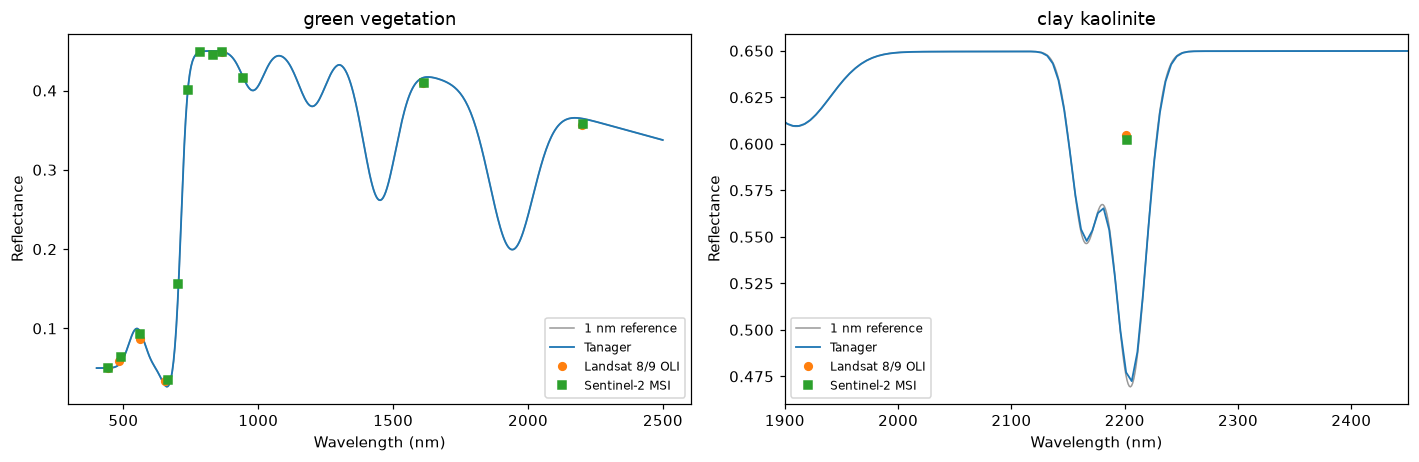

In [3]:
srf = hs.preprocess.SENSOR_SRF  # Gaussian approximations of multispectral band responses
sims = {"Tanager": hs.resample_spectral(lib_cube, tan_wl, tan_fwhm)}  # hyperspectral bands
for name, key in [("Landsat 8/9 OLI", "landsat89"), ("Sentinel-2 MSI", "sentinel2")]:
    c, w = zip(*srf[key].values())  # band centres and FWHM of the sensor
    sims[name] = hs.resample_spectral(lib_cube, c, w)  # broadband version of each spectrum

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), sharey=False)
for ax, k in zip(axes, [0, 4]):  # green vegetation and kaolinite-like clay
    ax.plot(lib.wavelengths, lib.spectra[k], color="0.6", lw=1, label="1 nm reference")
    for (name, s), m in zip(sims.items(), ["-", "o", "s"]):
        y = s.isel(x=k, y=0).values  # spectrum of material k at this sensor's bands
        ax.plot(hs.wavelengths(s), y, m, ms=5, lw=1.2, label=name)
    ax.set(title=lib.names[k].replace("_", " "), xlabel="Wavelength (nm)", ylabel="Reflectance")
    ax.legend(fontsize=8)
axes[1].set_xlim(1900, 2450)  # zoom on the clay doublet
plt.tight_layout()
plt.show()

In [4]:
# How deep does the 2205 nm clay feature look to each sensor? Continuum = straight line
# between the shoulders at 2120 and 2260 nm; depth = 1 - R(band) / R(continuum).
clay = 4  # library column of the clay spectrum
rows = []
for name, s in sims.items():
    wl = hs.wavelengths(s)  # band centres of this sensor
    y = s.isel(x=clay, y=0).values  # clay spectrum at those bands
    inside = (wl > 2120) & (wl < 2260)  # bands within the feature
    if not inside.any():
        rows.append({"sensor": name, "bands in 2120 to 2260 nm": 0, "feature depth": np.nan})
        continue
    cont = np.interp(wl[inside], [2120, 2260], np.interp([2120, 2260], lib.wavelengths, lib.spectra[clay]))
    rows.append({"sensor": name, "bands in 2120 to 2260 nm": int(inside.sum()),
                 "feature depth": float(np.max(1 - y[inside] / cont))})
ref = lib.spectra[clay]  # 1 nm reference
cont = np.interp(lib.wavelengths, [2120, 2260], np.interp([2120, 2260], lib.wavelengths, ref))
win = (lib.wavelengths > 2120) & (lib.wavelengths < 2260)
rows.append({"sensor": "1 nm reference", "bands in 2120 to 2260 nm": int(win.sum()),
             "feature depth": float(np.max(1 - ref[win] / cont[win]))})
pd.DataFrame(rows).round(3)

,sensor,bands in 2120 to 2260 nm,feature depth
0,Tanager,28,0.273
1,Landsat 8/9 OLI,1,0.069
2,Sentinel-2 MSI,1,0.073
3,1 nm reference,139,0.278


Tanager follows the reference closely and resolves both clay minima (2165 and 2205 nm). The
Landsat and Sentinel-2 SWIR2 bands are 175 to 190 nm wide: each sees the whole doublet as one
slightly darker value, and the feature depth drops to a fraction of the true depth, too shallow
to tell kaolinite from other clays or from dry vegetation. The same happens to the red edge, the
leaf water bands and every gas absorption.


## The GeoLattice cube: a laboratory example

The HACARUS dataset stores each band as a separate 8 bit PNG whose file name holds the wavelength
(`suger_salt_flour_1293nm.png`). That is a common pattern for laboratory and drone cameras, and a
good way to see how a cube is put together. The scene shows three white powders that look alike
to the eye: sugar, salt and flour.


In [5]:
def read_png_cube(folder):
    """Stack the *_<wavelength>nm.png band images of a HACARUS scene into a cube."""
    files = sorted(Path(folder).glob("*nm.png"), key=lambda p: float(re.search(r"_(\d+)nm", p.name)[1]))
    wl = [float(re.search(r"_(\d+)nm", p.name)[1]) for p in files]  # wavelength from each file name
    stack = np.stack([np.asarray(Image.open(p), dtype="float32") for p in files])  # (band, row, col)
    return hs.as_cube(stack, wl, name="dn")  # cube with a wavelength coordinate


ssf = read_png_cube(DATA / "archive/data/sugar_salt_flour")  # sugar, salt and flour scene
ssf  # dims, wavelength coordinate and values

<xarray.DataArray 'dn' (band: 96, y: 256, x: 192)> Size: 19MB
array([[[14., 14., 13., ..., 10., 10., 10.],
        [13., 13., 13., ...,  9.,  9.,  9.],
        [13., 13., 13., ...,  9.,  9.,  9.],
        ...,
        [13., 13., 13., ...,  9.,  9.,  9.],
        [13., 13., 13., ...,  9.,  9.,  9.],
        [13., 13., 13., ...,  9.,  9.,  9.]],

       [[14., 14., 14., ..., 10., 10., 10.],
        [13., 13., 13., ..., 10., 10., 10.],
        [13., 13., 13., ..., 10., 10., 10.],
        ...,
        [13., 13., 13., ..., 10., 10., 10.],
        [13., 13., 13., ...,  9.,  9.,  9.],
        [13., 13., 13., ...,  9.,  9.,  9.]],

       [[15., 15., 15., ..., 11., 11., 11.],
        [14., 14., 14., ..., 10., 10., 10.],
        [14., 14., 14., ..., 10., 10., 10.],
        ...,
...
        [ 4.,  4.,  4., ...,  3.,  3.,  3.],
        [ 4.,  4.,  4., ...,  3.,  3.,  3.],
        [ 4.,  4.,  4., ...,  3.,  3.,  3.]],

       [[ 4.,  4.,  4., ...,  3.,  3.,  3.],
        [ 4.,  4.,  4., ...,  3.,  3.,  3.],
        [ 3.,  3.,  3., ...,  3.,  3.,  3.],
        ...,
        [ 3.,  3.,  3., ...,  3.,  3.,  3.],
        [ 3.,  3.,  3., ...,  3.,  3.,  3.],
        [ 3.,  3.,  3., ...,  3.,  3.,  3.]],

       [[ 4.,  4.,  4., ...,  3.,  3.,  3.],
        [ 3.,  3.,  3., ...,  3.,  3.,  3.],
        [ 3.,  3.,  3., ...,  3.,  3.,  3.],
        ...,
        [ 3.,  3.,  3., ...,  2.,  3.,  3.],
        [ 3.,  3.,  3., ...,  2.,  2.,  2.],
        [ 3.,  3.,  3., ...,  2.,  2.,  3.]]],
      shape=(96, 256, 192), dtype=float32)
Coordinates:
  * band        (band) int64 768B 0 1 2 3 4 5 6 7 8 ... 88 89 90 91 92 93 94 95
    wavelength  (band) float64 768B 1.293e+03 1.302e+03 ... 2.205e+03 2.215e+03
Dimensions without coordinates: y, x

bands: 96 | wavelengths: [1293. 1302. 2215.] nm
band nearest 1450 nm: 16
1450 nm image shape: (256, 192)
bands between 2000 and 2100 nm: 11


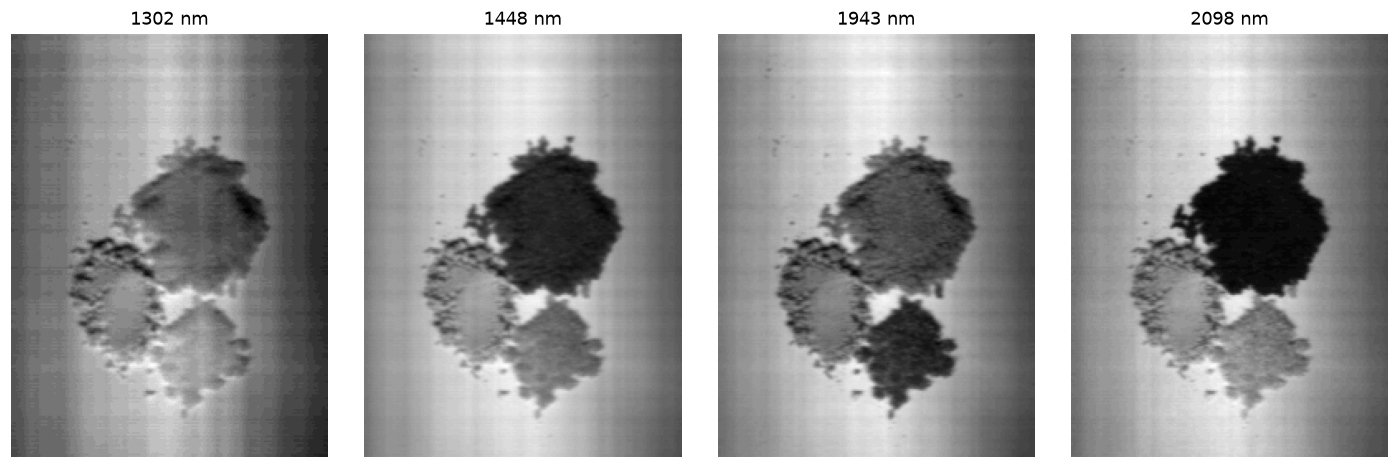

In [6]:
print("bands:", ssf.sizes["band"], "| wavelengths:", hs.wavelengths(ssf)[[0, 1, -1]], "nm")
print("band nearest 1450 nm:", hs.band_index(ssf, 1450))  # index of the closest band
print("1450 nm image shape:", hs.band_at(ssf, 1450).shape)  # one band as a 2-D image
print("bands between 2000 and 2100 nm:", hs.sel_range(ssf, 2000, 2100).sizes["band"])

fig, axes = plt.subplots(1, 4, figsize=(13, 4.2))
for ax, w in zip(axes, [1300, 1450, 1940, 2100]):  # four wavelengths
    ax.imshow(hs.band_at(ssf, w), cmap="gray")  # band image nearest to w
    ax.set_title(f"{float(hs.wavelengths(ssf)[hs.band_index(ssf, w)]):.0f} nm")
    ax.axis("off")
plt.tight_layout()
plt.show()

The powders swap brightness from band to band. Sugar (upper right) is dark from 1450 nm onward
and almost black near 2100 nm, where the O-H and C-H bonds of sucrose absorb. Salt (lower right)
is bright except near 1940 nm, where it turns dark: a water absorption, so this salt holds some
moisture. Flour (left) stays in between. Their positions follow the dataset's annotated preview: sugar upper right, flour left, salt lower
right. Circular regions of interest give the mean spectrum of each with `hs.mean_spectrum`.


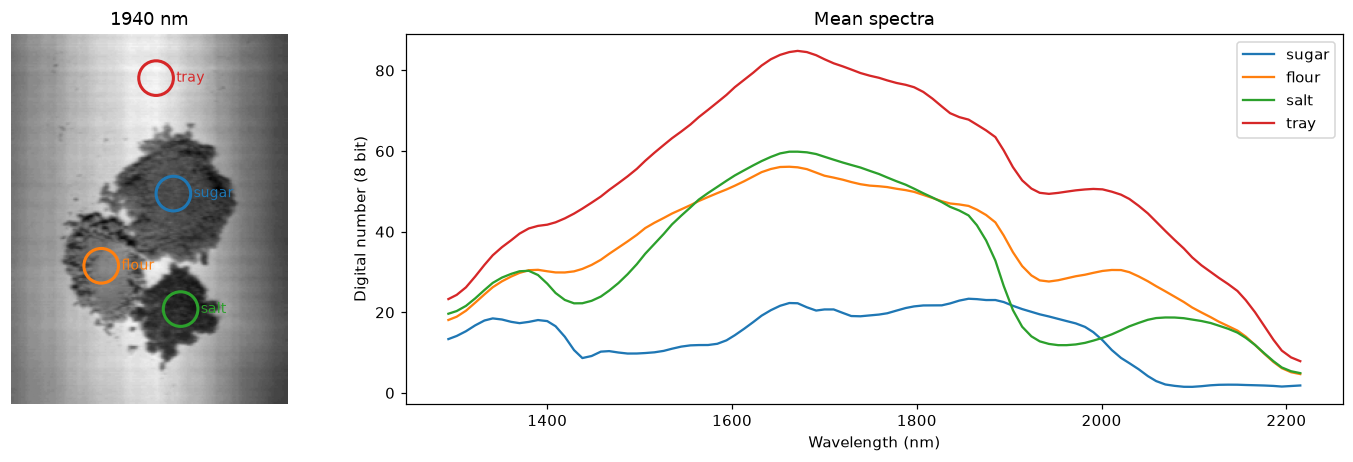

In [7]:
rr, cc = np.mgrid[:ssf.sizes["y"], :ssf.sizes["x"]]  # row and column of every pixel
rois = {"sugar": (110, 112), "flour": (160, 62), "salt": (190, 117), "tray": (30, 100)}  # (row, col) centres
masks = {k: (rr - r) ** 2 + (cc - c) ** 2 < 12 ** 2 for k, (r, c) in rois.items()}  # 12 px radius discs

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), gridspec_kw={"width_ratios": [1, 2.3]})
axes[0].imshow(hs.band_at(ssf, 1940), cmap="gray")  # a band where the powders differ
for (k, (r, c)), col in zip(rois.items(), ["C0", "C1", "C2", "C3"]):
    axes[0].add_patch(plt.Circle((c, r), 12, fill=False, color=col, lw=2))  # ROI outline
    axes[0].text(c + 14, r, k, color=col, fontsize=9, va="center")
    s = hs.mean_spectrum(ssf, masks[k])  # mean spectrum inside the ROI
    axes[1].plot(s.index, s.values, color=col, label=k)
axes[0].set_title("1940 nm"); axes[0].axis("off")
axes[1].set(xlabel="Wavelength (nm)", ylabel="Digital number (8 bit)", title="Mean spectra")
axes[1].legend()
plt.tight_layout()
plt.show()

The spectra confirm the images. Sugar is the darkest powder at every wavelength and falls to
almost zero beyond 2050 nm; salt has a sharp drop between about 1880 and 1950 nm and a smaller
dip near 1430 nm, both water bands; flour shows a dip near 1930 nm and stays moderately bright
beyond 2000 nm. These are raw 8 bit digital numbers, not reflectance: they include the lamp
spectrum and the camera response (the hump peaking near 1670 nm in the tray spectrum), and a white
reference would be needed to convert them. Even so, the shapes differ clearly, which is all spectral matching (notebook 09_05_06) and target
detection (notebook 09_05_08) need.


## The chapter data at a glance

The nine Tanager scenes come from Planet's open "core imagery" collection. `scenes.json` lists
their category, acquisition time, bounding box and STAC item.


In [8]:
scenes = pd.DataFrame(json.loads((TANAGER / "scenes.json").read_text()))  # one row per scene
scenes["date"] = scenes["datetime"].str[:10]  # acquisition date
scenes["lon"] = scenes["bbox"].apply(lambda b: round((b[0] + b[2]) / 2, 2))  # scene centre
scenes["lat"] = scenes["bbox"].apply(lambda b: round((b[1] + b[3]) / 2, 2))
scenes["sr_file"] = [next((TANAGER / f).glob("*_ortho_sr_hdf5.h5")) for f in scenes["folder"]]
scenes["size_MB"] = [round(p.stat().st_size / 2**20) for p in scenes["sr_file"]]  # SR file size
scenes[["category", "date", "lon", "lat", "folder", "size_MB"]]

,category,date,lon,lat,folder,size_MB
0,GHGs and Other Gases,2024-10-04,40.36,35.29,GHG-plumes/20241004_081921_28_4001,1284
1,Energy and Mining,2025-02-05,-103.90,32.88,energy-mining/20250205_175845_00_4001,1250
2,Natural Lands,2025-02-21,17.86,44.78,natural-lands/20250221_102048_16_4001,904
3,Agriculture,2025-02-24,-63.67,-22.18,agriculture/20250224_145149_32_4001,858
4,Coastal and Water Bodies,2025-02-25,-70.22,11.66,coastal-water-bodies/20250225_153627_16_4001,838
5,Urban,2025-04-23,-122.60,45.52,urban/20250423_193451_57_4001,1185
6,Snow and Ice,2025-04-11,-66.98,66.35,snow-ice/20250411_163421_16_4001,1209
7,Fire,2024-12-15,-118.72,34.01,fire/20241215_185916_33_4001,785
8,ROCX 2025,2025-09-19,-77.47,43.25,ROCX2025/20250919_170233_04_4001,1252


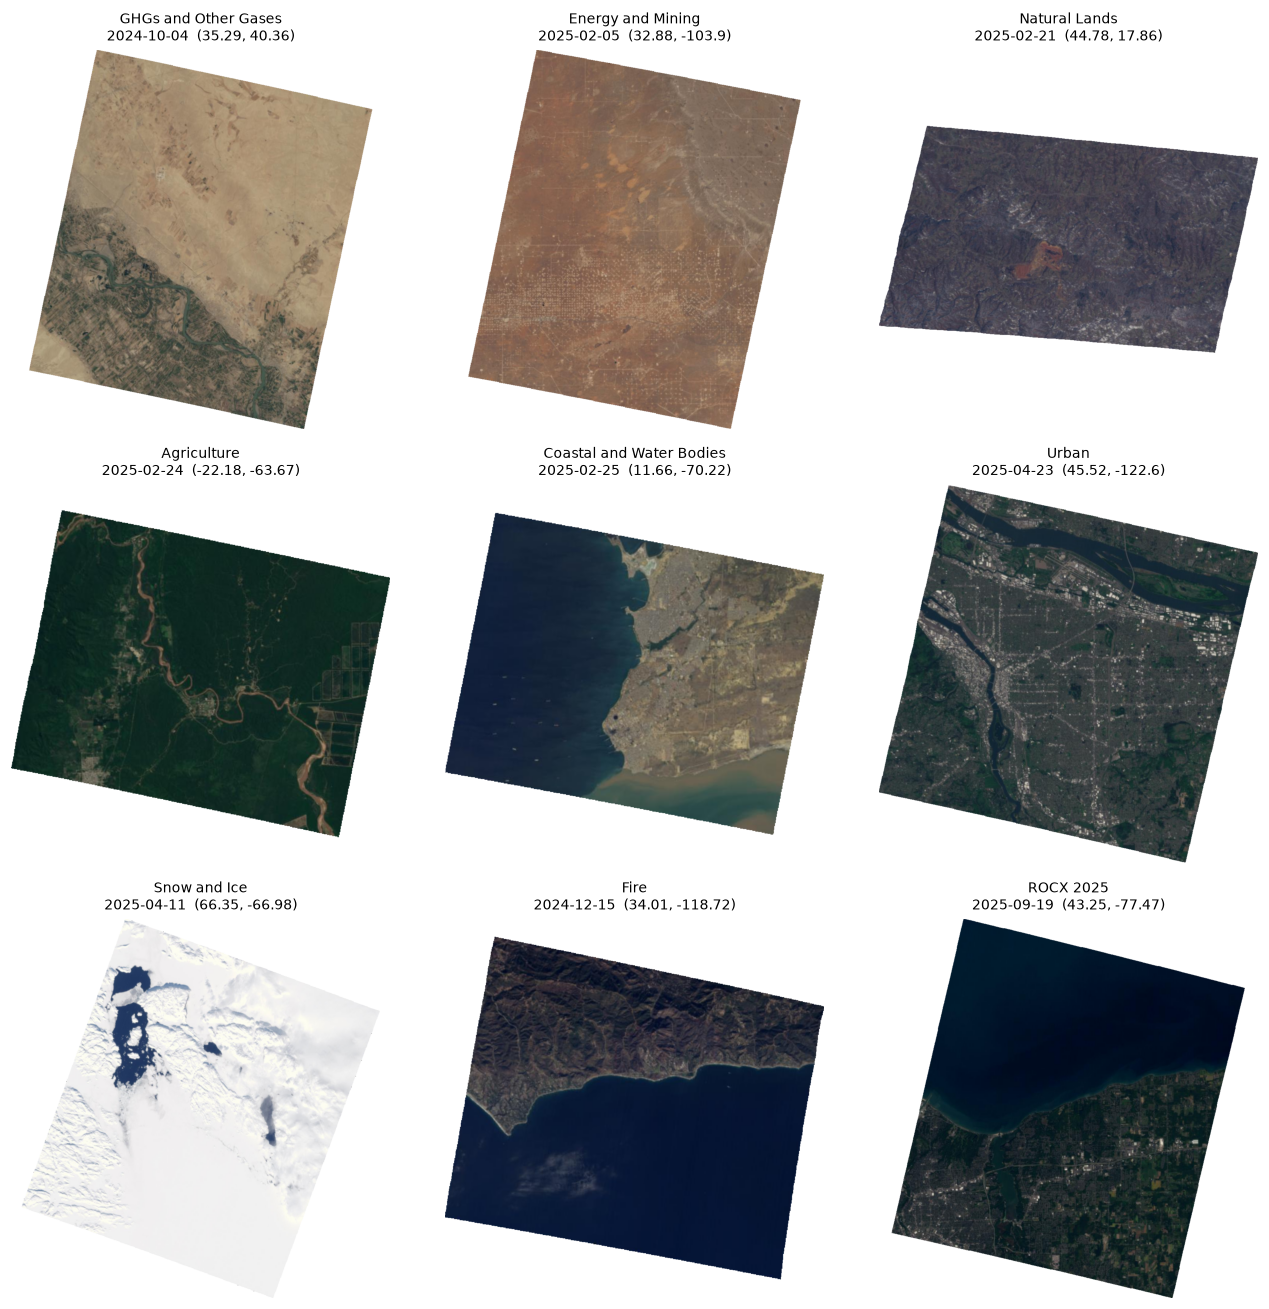

In [9]:
fig, axes = plt.subplots(3, 3, figsize=(12, 12))
for ax, (_, s) in zip(axes.ravel(), scenes.iterrows()):
    thumb = next((TANAGER / s["folder"]).glob("*_thumb.png"))  # true colour preview
    ax.imshow(Image.open(thumb))
    ax.set_title(f"{s['category']}\n{s['date']}  ({s['lat']}, {s['lon']})", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

The scenes span seven climates and most hyperspectral applications: the Deir ez-Zor oil region of
Syria (methane plumes), oil and gas pads of the Permian Basin in New Mexico, hills of Bosnia and
Herzegovina, Gran Chaco forest and fields on the Bolivia and Argentina border, the Paraguaná
Peninsula of Venezuela (refinery, sea and a sediment plume), Portland in Oregon, sea ice and snow on
Baffin Island, the Malibu coast in December 2024 (burn scar of that month's Franklin Fire) and
Rochester, New York, site of the ROCX 2025 calibration campaign.

The other datasets complete the picture. The table below is computed from the files themselves.


In [10]:
ohs_dir = next((DATA / "10m_OH2_Hyperspectral_Sample/Spanish-OHS").iterdir())  # OHS scene folder
with rasterio.open(next(ohs_dir.glob("*_B1_*.tif"))) as src:  # one OHS band file
    ohs_shape = (src.height, src.width)  # rows, columns
ohs = hs.read_ohs(ohs_dir, window=(slice(0, 1), slice(0, 1)))  # 1 x 1 pixel, all 32 bands
pavia = np.load(DATA / "Pavia/pavia.npy", mmap_mode="r")  # (rows, cols, bands), not loaded into memory

summary = pd.DataFrame([
    {"dataset": "Tanager (agriculture)", "bands": tan_wl.size, "rows x cols": "663 x 775",
     "range (nm)": f"{tan_wl[0]:.0f} to {tan_wl[-1]:.0f}", "pixel": "30 m", "units": "reflectance"},
    {"dataset": "OHS (Spain)", "bands": ohs.sizes["band"], "rows x cols": f"{ohs_shape[0]} x {ohs_shape[1]}",
     "range (nm)": f"{hs.wavelengths(ohs)[0]:.0f} to {hs.wavelengths(ohs)[-1]:.0f}", "pixel": "10 m",
     "units": "DN (L1)"},
    {"dataset": "Pavia Centre (ROSIS)", "bands": pavia.shape[2], "rows x cols": f"{pavia.shape[0]} x {pavia.shape[1]}",
     "range (nm)": "430 to 860", "pixel": "1.3 m", "units": "scaled reflectance (uint16)"},
    {"dataset": "HACARUS sugar salt flour", "bands": ssf.sizes["band"],
     "rows x cols": f"{ssf.sizes['y']} x {ssf.sizes['x']}",
     "range (nm)": f"{hs.wavelengths(ssf)[0]:.0f} to {hs.wavelengths(ssf)[-1]:.0f}", "pixel": "lab (sub mm)",
     "units": "DN (8 bit)"},
])
summary

,dataset,bands,rows x cols,range (nm),pixel,units
0,Tanager (agriculture),426,663 x 775,376 to 2499,30 m,reflectance
1,OHS (Spain),32,5056 x 5056,466 to 940,10 m,DN (L1)
2,Pavia Centre (ROSIS),102,1096 x 715,430 to 860,1.3 m,scaled reflectance (uint16)
3,HACARUS sugar salt flour,96,256 x 192,1293 to 2215,lab (sub mm),DN (8 bit)


Band placement differs as much as band count. Each row below is one sensor; bars span one FWHM
where it is known, dots mark band centres otherwise. The Pavia centres are approximated as evenly
spaced, since the file carries no wavelength table.


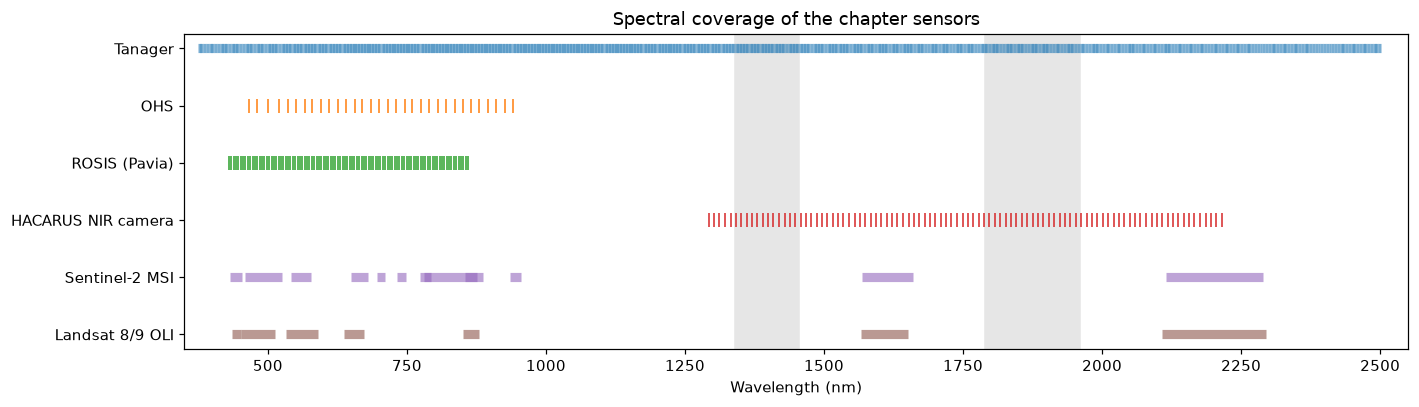

In [11]:
fig, ax = plt.subplots(figsize=(13, 3.8))
rows = [("Tanager", tan_wl, tan_fwhm), ("OHS", hs.wavelengths(ohs), None),
        ("ROSIS (Pavia)", np.linspace(430, 860, pavia.shape[2]), None),
        ("HACARUS NIR camera", hs.wavelengths(ssf), None),
        ("Sentinel-2 MSI", *map(np.array, zip(*srf["sentinel2"].values()))),
        ("Landsat 8/9 OLI", *map(np.array, zip(*srf["landsat89"].values())))]
for i, (name, c, w) in enumerate(rows):
    if w is None:
        ax.plot(c, np.full(c.size, i), "|", ms=9, color=f"C{i}")  # band centres only
    else:
        ax.hlines(np.full(c.size, i), c - w / 2, c + w / 2, lw=6, color=f"C{i}", alpha=0.6)  # FWHM bars
for lo, hi in [(1340, 1455), (1790, 1960)]:
    ax.axvspan(lo, hi, color="0.9", zorder=0)  # opaque water vapour bands
ax.set_yticks(range(len(rows)), [r[0] for r in rows])
ax.set(xlabel="Wavelength (nm)", xlim=(350, 2550), title="Spectral coverage of the chapter sensors")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

## A first look at a Tanager scene

`hs.read_tanager` reads the HDF-EOS5 file, attaches wavelengths, FWHM and good band flags, sets the
fill value and no-data pixels to NaN and places the cube on its UTM grid. A `window` (row and
column slices), `bbox`, `bands` or `wavelength_range` reads only part of the file. Here a
300 by 300 pixel window (9 by 9 km) of the agriculture scene is read with all bands, about 150 MB.


In [12]:
WIN = (slice(180, 480), slice(240, 540))  # rows and columns of the window
cube = hs.read_tanager(sr_agri, window=WIN)  # surface reflectance, all 426 bands
print(cube.dims, cube.shape, "| CRS:", cube.rio.crs, "| units:", cube.attrs["units"])
print("good bands:", int(cube["good"].sum()), "of", cube.sizes["band"])
cube

('band', 'y', 'x') (426, 300, 300) | CRS: EPSG:32720 | units: Unitless
good bands: 368 of 426


<xarray.DataArray 'surface_reflectance' (band: 426, y: 300, x: 300)> Size: 153MB
array([[[ 0.06588556,  0.05553   ,  0.0509092 , ...,  0.05735924,
          0.05950746,  0.06022785],
        [ 0.06723303,  0.08184884,  0.0509092 , ...,  0.05738014,
          0.0552189 ,  0.05509504],
        [ 0.05950201,  0.06020816,  0.06686234, ...,  0.06170927,
          0.05569411,  0.05509504],
        ...,
        [ 0.06133678,  0.06047076,  0.060533  , ...,  0.05784278,
          0.05267708,  0.05343123],
        [ 0.05541341,  0.05895338,  0.05895483, ...,  0.05048819,
          0.05446123,  0.05192246],
        [ 0.0548837 ,  0.05370027,  0.05895483, ...,  0.04631779,
          0.04670545,  0.05311254]],

       [[ 0.06543393,  0.063095  ,  0.07016334, ...,  0.05797268,
          0.06161525,  0.05998835],
        [ 0.06523599,  0.07931174,  0.07016334, ...,  0.05768103,
          0.05691753,  0.05478174],
        [ 0.06092052,  0.07480283,  0.0810383 , ...,  0.06030399,
          0.05490314,  0.05478174],
...
        [ 0.03035763,  0.04544654,  0.06267712, ...,  0.02914475,
          0.00475216,  0.00705135],
        [ 0.0158594 ,  0.02170332,  0.03070807, ...,  0.01784977,
          0.0105112 ,  0.00754654],
        [-0.00266733,  0.02148094,  0.03070807, ..., -0.00173913,
          0.01462854,  0.02345524]],

       [[ 0.05132443,  0.11869162,  0.14038138, ...,  0.02857878,
          0.03480563,  0.00452703],
        [ 0.02745818,  0.09306484,  0.14038138, ...,  0.01316916,
          0.01535989,  0.00711796],
        [ 0.04985031,  0.1006022 ,  0.12478207, ...,  0.01704719,
          0.01845938,  0.00711796],
        ...,
        [ 0.03057979,  0.04523857,  0.06278548, ...,  0.02909105,
          0.00417659,  0.00686102],
        [ 0.01564855,  0.02132749,  0.0302573 , ...,  0.01734684,
          0.01021126,  0.00727946],
        [-0.00305221,  0.02132685,  0.0302573 , ..., -0.00262485,
          0.01417134,  0.0231659 ]]], shape=(426, 300, 300), dtype=float32)
Coordinates:
  * band         (band) int64 3kB 0 1 2 3 4 5 6 ... 419 420 421 422 423 424 425
    wavelength   (band) float64 3kB 376.4 381.4 386.4 ... 2.494e+03 2.499e+03
    fwhm         (band) float64 3kB 5.39 5.42 5.45 5.48 ... 5.21 5.21 5.2 5.2
    good         (band) bool 426B True True True True ... True True True True
  * y            (y) float64 2kB 7.551e+06 7.551e+06 ... 7.542e+06 7.542e+06
  * x            (x) float64 2kB 4.267e+05 4.267e+05 ... 4.356e+05 4.357e+05
    spatial_ref  int64 8B 0
Attributes:
    sensor:   Tanager
    units:    Unitless
    product:  20250224_145149_32_4001_ortho_sr_hdf5.h5

bad band ranges (nm): [(1342, 1438), (1783, 1967)]


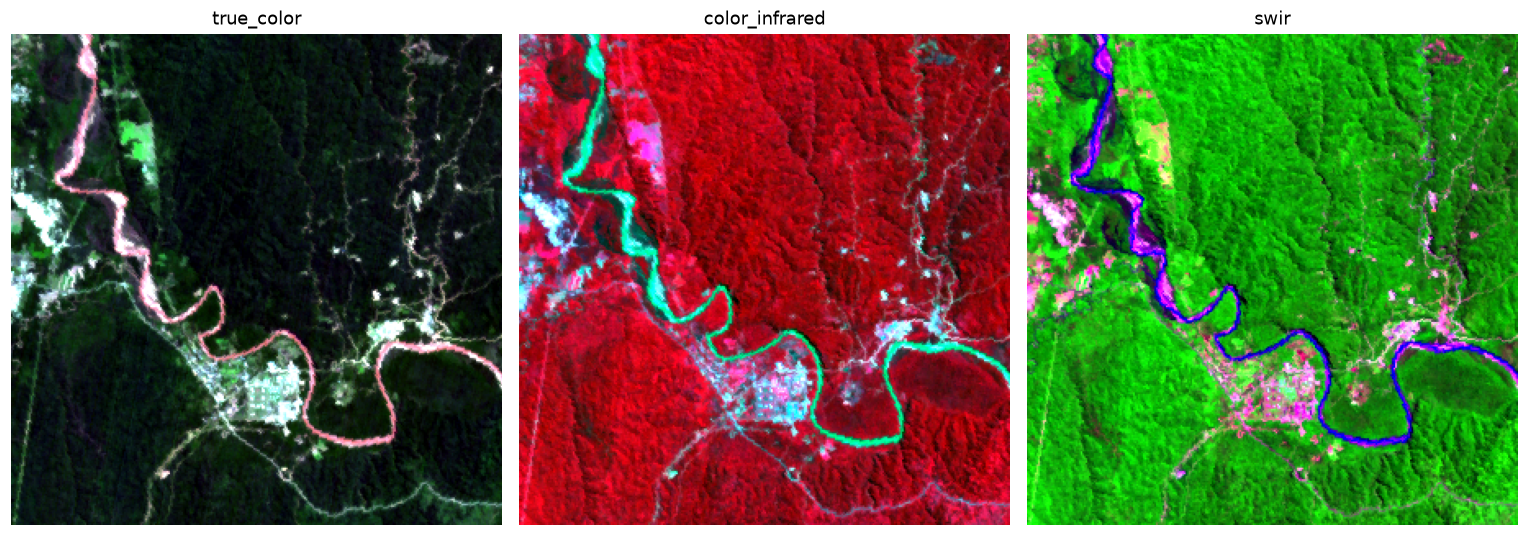

In [13]:
bad = hs.wavelengths(cube)[~cube["good"].values]  # wavelengths flagged bad by the product
edges = np.flatnonzero(np.diff(np.r_[-10, bad]) > 6)  # start of each run of bad bands
runs = [(bad[i], bad[j - 1]) for i, j in zip(edges, list(edges[1:]) + [len(bad)])]
print("bad band ranges (nm):", [(round(a), round(b)) for a, b in runs])

fig, axes = plt.subplots(1, 3, figsize=(14, 4.8))
for ax, comp in zip(axes, ["true_color", "color_infrared", "swir"]):
    hs.plot_rgb(cube, comp, ax=ax)  # composite from the bands nearest to the preset wavelengths
plt.tight_layout()
plt.show()

The window shows Chaco forest, a meandering river with a heavy sediment load (pink in true colour),
a town and some clearings. In colour infrared (860, 650, 550 nm) the forest is red and the river
cyan; in the SWIR composite (2200, 860, 650 nm) the town, roads and cleared ground turn pink and
the river blue, because water absorbs strongly at 2200 nm.

The product flags 58 bands as bad, exactly the two opaque water vapour windows (1342 to 1438 nm and
1783 to 1967 nm). The bands below 400 nm and beyond 2450 nm are kept as good but are noisy;
`hs.bad_bands` (notebook 09_05_02) adds them to the mask.


['aerosol_optical_depth', 'beta_cirrus_mask', 'beta_cloud_mask', 'column_water_vapour', 'nodata_pixels', 'sensor_azimuth', 'sensor_to_ground_path_length', 'sensor_zenith', 'sun_azimuth', 'sun_zenith', 'time']


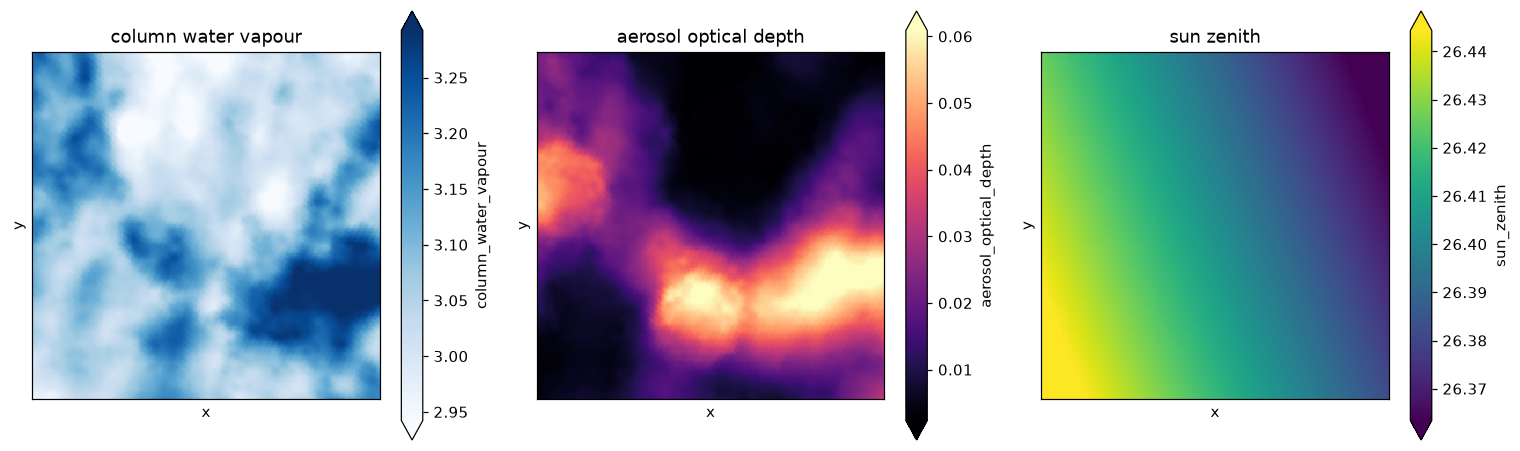

cloud pixels: 3 | cirrus pixels: 0


In [14]:
anc = hs.read_tanager_ancillary(sr_agri, window=WIN)  # 2-D layers on the same grid
print(list(anc.data_vars))
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, (v, cmap) in zip(axes, [("column_water_vapour", "Blues"), ("aerosol_optical_depth", "magma"),
                                ("sun_zenith", "viridis")]):
    anc[v].plot(ax=ax, cmap=cmap, robust=True)  # map of each retrieved or geometric layer
    ax.set_title(v.replace("_", " ")); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()
print("cloud pixels:", int(anc["beta_cloud_mask"].sum()), "| cirrus pixels:", int(anc["beta_cirrus_mask"].sum()))

Water vapour and aerosol optical depth are retrieved during atmospheric correction and change
smoothly across the scene; the window is practically cloud free (3 cloud pixels of 90,000). These layers are useful as quality checks and
as covariates, and the cloud masks can be applied directly with `read_tanager(mask_clouds=True)`.


## Radiance, reflectance and the atmosphere

The same window read from the ortho radiance product shows what the sensor actually measured.
Pixels are picked by NDVI computed from two bands: a dense green canopy (high NDVI) and a bare
field (low NDVI, bright in the SWIR).


In [15]:
red, nir, swir = (hs.band_at(cube, w) for w in (650, 860, 2200))  # bands nearest 650, 860, 2200 nm
ndvi = (nir - red) / (nir + red)  # normalised difference vegetation index
veg_rc = np.unravel_index(np.nanargmax(ndvi.where(ndvi < ndvi.quantile(0.999)).values), ndvi.shape)  # dense canopy
soil_score = swir.where(ndvi < 0.2)  # bright SWIR among sparsely vegetated pixels
soil_rc = np.unravel_index(np.nanargmin(abs(soil_score - soil_score.quantile(0.9)).values), ndvi.shape)
print("vegetation pixel (row, col):", veg_rc, "NDVI", round(float(ndvi[veg_rc]), 2))
print("bare soil pixel (row, col):", soil_rc, "NDVI", round(float(ndvi[soil_rc]), 2))

rad_file = next(sr_agri.parent.glob("*_ortho_radiance_hdf5.h5"))  # TOA radiance product
rad = hs.read_tanager(rad_file, window=WIN)  # same window, radiance in W m-2 sr-1 um-1
print(rad.attrs["units"], rad.shape)

vegetation pixel (row, col): (np.int64(89), np.int64(64)) NDVI 0.89
bare soil pixel (row, col): (np.int64(195), np.int64(280)) NDVI 0.17


W/(m^2 sr um) (426, 300, 300)


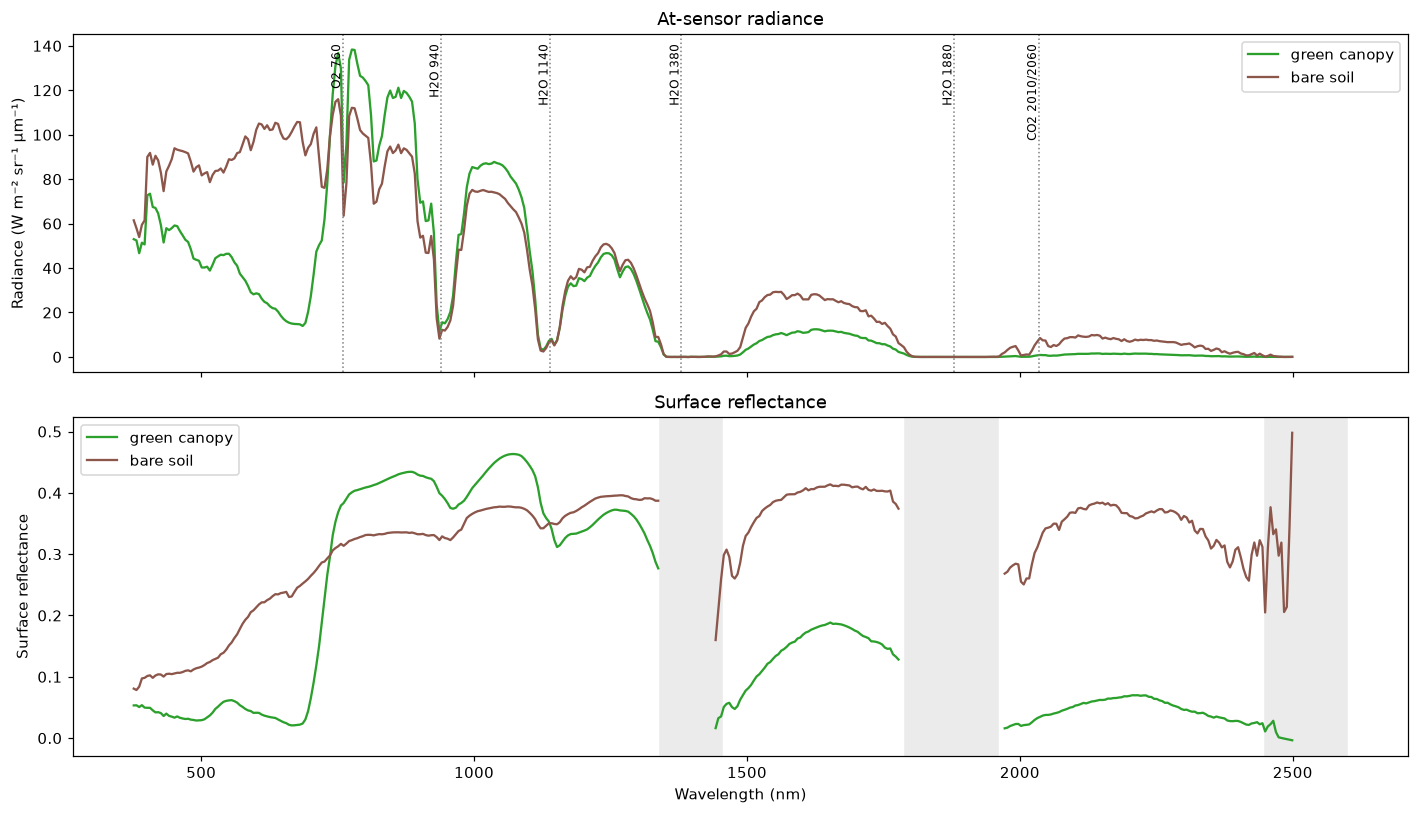

In [16]:
wl = hs.wavelengths(cube)  # band centres (nm)
features = {"O2 760": 760, "H2O 940": 940, "H2O 1140": 1140, "H2O 1380": 1380,
            "H2O 1880": 1880, "CO2 2010/2060": 2035}  # atmospheric absorption features
fig, axes = plt.subplots(2, 1, figsize=(13, 7.5), sharex=True)
for (name, (r, c)), col in zip([("green canopy", veg_rc), ("bare soil", soil_rc)], ["C2", "C5"]):
    axes[0].plot(wl, rad.values[:, r, c], color=col, label=name)  # radiance spectrum
    refl = np.where(cube["good"].values, cube.values[:, r, c], np.nan)  # reflectance, bad bands hidden
    axes[1].plot(wl, refl, color=col, label=name)
for name, w in features.items():
    axes[0].axvline(w, color="0.5", ls=":", lw=1)
    axes[0].text(w, axes[0].get_ylim()[1] * 0.97, name, rotation=90, va="top", ha="right", fontsize=8)
for lo, hi in hs.preprocess.WATER_VAPOUR_RANGES:
    axes[1].axvspan(lo, hi, color="0.92", zorder=0)  # bands dropped as bad
axes[0].set(ylabel="Radiance (W m⁻² sr⁻¹ µm⁻¹)", title="At-sensor radiance")
axes[1].set(ylabel="Surface reflectance", xlabel="Wavelength (nm)", title="Surface reflectance")
axes[0].legend(); axes[1].legend()
plt.tight_layout()
plt.show()

Radiance follows the solar spectrum: it is largest in the visible and NIR and falls steeply into
the SWIR, and the atmosphere cuts deep notches at the oxygen A band, the water vapour bands and
the CO₂ pair. Both pixels share those notches, and radiance drops to zero in the opaque windows
near 1400 and 1900 nm. After correction the reflectance spectra show the surface. The canopy has
the green peak, the red absorption, the steep red edge near 700 nm, a high NIR plateau with dips
near 970 and 1200 nm (leaf water) and much lower SWIR reflectance, again because of leaf water.
The soil rises from the visible to a plateau of about 0.4 between 1500 and 2200 nm and declines
slowly beyond it. The spikes beside the bad band windows and beyond 2450 nm are residual noise
from atmospheric correction.


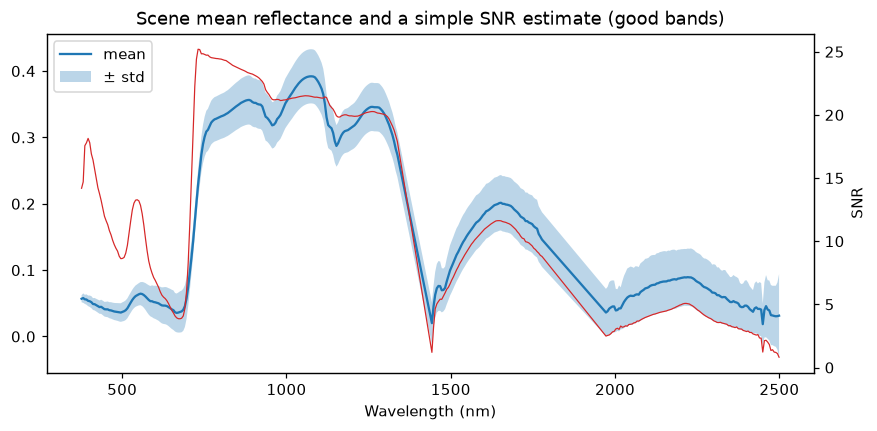

,wavelength,mean,snr
367,2499.00,0.03,0.81
366,2494.04,0.03,1.11
365,2489.09,0.03,1.20
71,730.97,0.23,25.20
72,735.98,0.25,25.17
74,745.99,0.29,24.84


In [17]:
stats = hs.band_stats(cube.isel(band=np.flatnonzero(cube["good"].values)))  # per band statistics, good bands
ax = hs.plot_band_stats(stats)  # mean, spread and SNR per band
ax.set_title("Scene mean reflectance and a simple SNR estimate (good bands)")
plt.show()
stats.iloc[stats["snr"].nsmallest(3).index.tolist() + stats["snr"].nlargest(3).index.tolist()][
    ["wavelength", "mean", "snr"]].round(2)

`band_stats` estimates noise from differences between neighbouring pixels, so its SNR is a lower
bound that also includes real texture. It still shows the expected pattern: highest on the NIR plateau
(about 25 near 730 to 750 nm), low wherever the scene is dark (the red chlorophyll absorption near
680 nm, the edges of the water bands near 1440 and 1970 nm) and lowest beyond 2480 nm, where few
photons arrive.


## Spectral signatures across Tanager scenes

Each scene contributes one material. A pixel is chosen by a simple rule on a few bands (read with
`bands=` so only seven of the 426 bands are loaded), then the full spectrum is read as the mean of
a 3 by 3 pixel window around it.


In [18]:
probe_idx = [hs.band_index(probe, w) for w in (560, 650, 860, 1650, 2200)]  # green, red, NIR, SWIR1, SWIR2


def nd(a, b):
    """Normalised difference of two band arrays."""
    return (a - b) / (a + b)


def closest(score, q):
    """(row, col) of the valid pixel whose score is nearest to its q-th quantile."""
    target = np.nanquantile(score, q)
    return np.unravel_index(np.nanargmin(np.abs(score - target)), score.shape)


rules = {  # material: (scene folder prefix, rule returning (row, col))
    "green vegetation": ("agriculture", lambda G, R, N, S1, S2: closest(nd(N, R), 0.995)),
    "bare soil (Permian Basin)": ("energy-mining",
                                  lambda G, R, N, S1, S2: closest(np.where(nd(N, R) < 0.12, S1, np.nan), 0.5)),
    "sea water": ("coastal-water-bodies", lambda G, R, N, S1, S2: closest(np.where(nd(G, N) > 0.3, N, np.nan), 0.5)),
    "snow": ("snow-ice", lambda G, R, N, S1, S2: closest(np.where(nd(G, S1) > 0.8, G, np.nan), 0.5)),
    "urban (roofs and roads)": ("urban",
                                lambda G, R, N, S1, S2: closest(np.where((nd(N, R) < 0.1) & (nd(G, N) < 0), S1, np.nan), 0.5)),
    "burn scar (Franklin Fire)": ("fire",
                                  lambda G, R, N, S1, S2: closest(np.where(N > 0.08, nd(N, S2), np.nan), 0.002)),
    "desert (Syria)": ("GHG-plumes", lambda G, R, N, S1, S2: closest(np.where(nd(N, R) < 0.12, S1, np.nan), 0.5)),
}

sigs, picks = {}, {}
for material, (prefix, rule) in rules.items():
    f = scenes.loc[scenes["folder"].str.startswith(prefix), "sr_file"].iloc[0]  # SR file of the scene
    few = hs.read_tanager(f, bands=probe_idx)  # five bands of the whole scene
    r, c = rule(*few.values)  # pixel chosen by the rule
    win = hs.read_tanager(f, window=(slice(max(r - 1, 0), r + 2), slice(max(c - 1, 0), c + 2)))  # 3 x 3 pixels
    sigs[material] = hs.mean_spectrum(win).where(win["good"].values)  # mean spectrum, bad bands NaN
    picks[material] = (prefix, int(r), int(c))
pd.DataFrame(picks, index=["scene", "row", "col"]).T

,scene,row,col
green vegetation,agriculture,331,719
bare soil (Permian Basin),energy-mining,695,124
sea water,coastal-water-bodies,237,211
snow,snow-ice,615,256
urban (roofs and roads),urban,671,452
burn scar (Franklin Fire),fire,185,512
desert (Syria),GHG-plumes,396,789


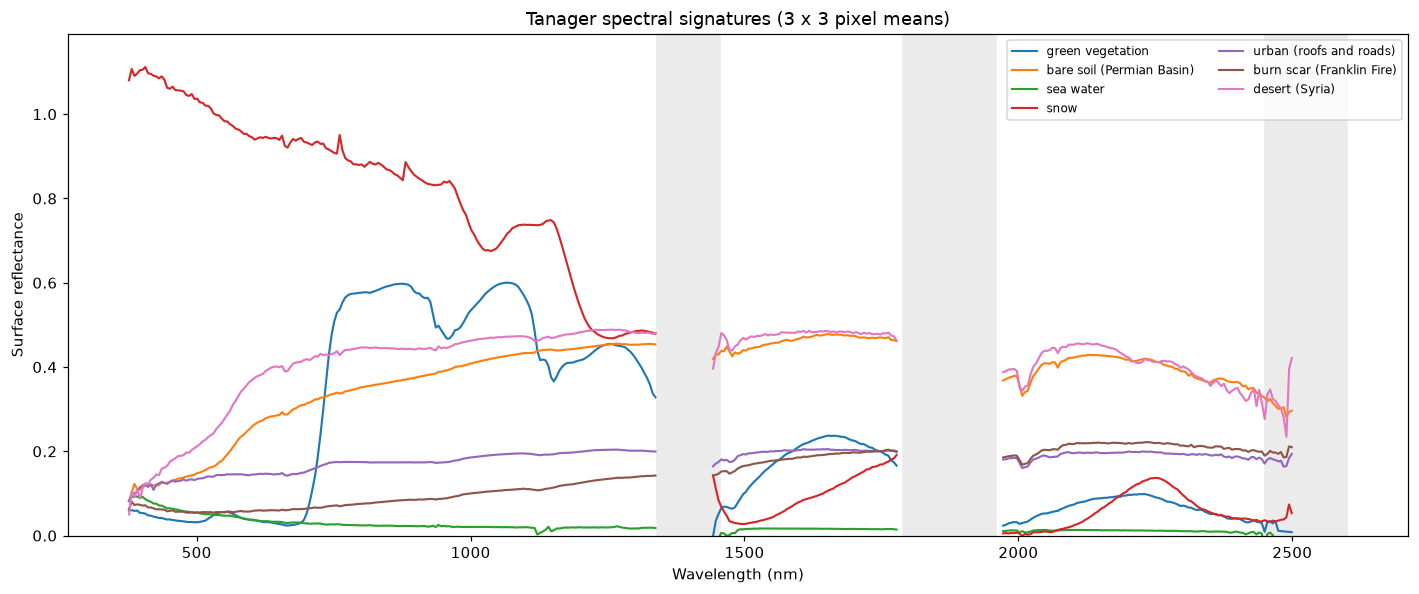

In [19]:
fig, ax = plt.subplots(figsize=(13, 5.5))
for i, (material, s) in enumerate(sigs.items()):
    ax.plot(s.index, s.values, lw=1.4, color=f"C{i}", label=material)  # one signature per scene
for lo, hi in hs.preprocess.WATER_VAPOUR_RANGES:
    ax.axvspan(lo, hi, color="0.92", zorder=0)  # bad band windows
ax.set(xlabel="Wavelength (nm)", ylabel="Surface reflectance", ylim=(0, None),
       title="Tanager spectral signatures (3 x 3 pixel means)")
ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

In [20]:
# A few diagnostic values per signature: visible brightness, NIR/red ratio and SWIR behaviour.
tab = pd.DataFrame({m: {"R560": s.iloc[hs.band_index(probe, 560)], "R650": s.iloc[hs.band_index(probe, 650)],
                        "R860": s.iloc[hs.band_index(probe, 860)], "R1650": s.iloc[hs.band_index(probe, 1650)],
                        "R2200": s.iloc[hs.band_index(probe, 2200)]} for m, s in sigs.items()}).T
tab["NDVI"] = (tab["R860"] - tab["R650"]) / (tab["R860"] + tab["R650"])  # vegetation
tab["NDSI"] = (tab["R560"] - tab["R1650"]) / (tab["R560"] + tab["R1650"])  # snow
tab["NBR"] = (tab["R860"] - tab["R2200"]) / (tab["R860"] + tab["R2200"])  # burn ratio
tab.round(3)

,R560,R650,R860,R1650,R2200,NDVI,NDSI,NBR
green vegetation,0.055,0.027,0.596,0.236,0.097,0.912,-0.623,0.720
bare soil (Permian Basin),0.200,0.286,0.366,0.477,0.418,0.122,-0.409,-0.067
sea water,0.047,0.033,0.023,0.016,0.012,-0.172,0.484,0.305
snow,0.976,0.939,0.858,0.103,0.110,-0.045,0.808,0.773
urban (roofs and roads),0.145,0.146,0.174,0.205,0.200,0.087,-0.170,-0.069
burn scar (Franklin Fire),0.057,0.060,0.083,0.192,0.220,0.163,-0.541,-0.453
desert (Syria),0.296,0.399,0.444,0.486,0.423,0.053,-0.242,0.024


Each class has its own shape:

- **Green vegetation** has the red edge and the highest NIR to red contrast (NDVI near 0.9).
- **Bare soil** and **desert** rise steeply through the visible (iron oxides make them red), level
  off in the SWIR and decline beyond 2200 nm, where clays and carbonates absorb. The Syrian desert
  is the brightest.
- **Sea water** is dark everywhere and close to zero beyond 700 nm.
- **Snow** is very bright in the visible (0.9 to 1.1; values slightly above 1 come from the viewing
  geometry and the correction), has ice absorptions near 1030 and 1260 nm and falls to a few
  percent beyond 1500 nm. Its NDSI is the highest of all classes.
- **Urban** surfaces are flat and moderately bright, a mixture of roofs, asphalt and concrete.
- **Burn scar** pixels are dark in the NIR and relatively bright near 2200 nm, so their burn ratio
  (NBR) is the lowest.

The rules picked typical pixels, not pure ones: at 30 m most pixels mix several materials, and the
urban spectrum in particular is an average of roofs, roads and trees. Spectral matching, unmixing and detection later in the chapter
work with exactly these differences in shape.


## Interactive exploration

`hs.spectral_viewer` draws a composite next to the spectra of chosen points, and
`hs.wavelength_slider` steps through the bands. Both return Plotly figures. To keep the notebook
small the cube is thinned to every third pixel and the slider shows every 25th band.


In [21]:
small = cube.isel(y=slice(None, None, 3), x=slice(None, None, 3))  # 100 x 100 pixels
pts = [(float(cube.x[c]), float(cube.y[r])) for r, c in (veg_rc, soil_rc)]  # canopy and soil pixels (map x, y)
fig = hs.spectral_viewer(small, pts, composite="color_infrared")
fig.update_layout(width=950, height=420)
fig.show()

In [22]:
fig = hs.wavelength_slider(small.isel(band=np.flatnonzero(small["good"].values)), step=25)  # good bands only
fig.update_layout(width=520, height=520)
fig.show()

## Summary and exercises

**Key points**

- Imaging spectrometers record hundreds of narrow contiguous bands; FWHM, sampling and SNR decide
  which absorption features can be resolved. Broad multispectral bands average away features such
  as the 2165 and 2205 nm clay doublet.
- A hyperspectral cube is `(band, y, x)` with a wavelength axis; in GeoLattice every function works on
  that layout and selects bands by wavelength (`band_at`, `band_index`, `sel_range`).
- Sensors measure radiance; surface reflectance requires atmospheric correction. Oxygen, water
  vapour and CO₂ leave absorption bands, and the opaque water vapour windows are flagged as bad
  bands.
- `hs.read_tanager` reads Tanager ortho and basic products with subsetting by window, bbox, bands
  or wavelength; `hs.read_tanager_ancillary` returns the masks, water vapour, aerosol and geometry.
- Vegetation, soil, water, snow, urban surfaces and burn scars have distinct spectral shapes, the
  basis of every method in this chapter.

**`geolattice.rsense.hyperspectral` functions used:** `synthetic_library`, `as_cube`,
`resample_spectral`, `wavelengths`, `band_index`, `band_at`, `sel_range`, `mean_spectrum`,
`read_tanager`, `read_tanager_ancillary`, `read_ohs`, `plot_rgb`, `band_stats`, `plot_band_stats`,
`spectral_viewer`, `wavelength_slider`, plus the tables `preprocess.SENSOR_SRF` and
`preprocess.WATER_VAPOUR_RANGES`.

**Exercises**

1. Repeat the narrow band comparison for the carbonate spectrum (`carbonate_calcite`, feature near
   2340 nm). Which multispectral band, if any, sees it?
2. Build cubes for the `rice` and `coffee` HACARUS scenes with `read_png_cube` and plot the mean
   spectra of two objects in each.
3. Read the ROCX 2025 scene with `bbox=` around Lake Ontario's shore and compare the water spectrum
   with the Venezuelan sea water spectrum above. What does the difference near 550 to 700 nm
   suggest?
4. Read the urban scene with `mask_clouds=True` and count how many pixels the cloud and cirrus
   masks remove.
5. Using `rad` and `cube`, divide radiance by reflectance for the canopy pixel. What does the
   result approximate, and why does it fall to near zero in the opaque water bands?

## References

- Goetz, A. F. H., Vane, G., Solomon, J. E. and Rock, B. N. (1985). Imaging spectrometry for Earth
  remote sensing. *Science*, 228(4704), 1147 to 1153.
- Green, R. O. et al. (1998). Imaging spectroscopy and the Airborne Visible/Infrared Imaging
  Spectrometer (AVIRIS). *Remote Sensing of Environment*, 65(3), 227 to 248.
- Clark, R. N. et al. (2003). Imaging spectroscopy: Earth and planetary remote sensing with the
  USGS Tetracorder and expert systems. *Journal of Geophysical Research*, 108(E12), 5131.
- Guanter, L. et al. (2015). The EnMAP spaceborne imaging spectroscopy mission for Earth
  observation. *Remote Sensing*, 7(7), 8830 to 8857.
- Green, R. O. et al. (2020). The Earth Surface Mineral Dust Source Investigation: an Earth science
  imaging spectroscopy mission. *IEEE Aerospace Conference*.
- Planet Labs PBC. Tanager core imagery, open sample data (STAC catalogue at planet.com/data/stac).
- HACARUS Inc. Hyperspectral image open dataset (CC BY-NC 4.0).
